In [2]:
# 1. Utilize Libraries/Dataset

# Import the necessary libraries
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import cifar10
import seaborn as sns
import pandas as pd
from matplotlib.pyplot import figure

# Load the CIFAR-10 dataset
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Print basic information about the dataset
print("Training data shape:", x_train.shape)
print("Training labels shape:", y_train.shape)
print("Test data shape:", x_test.shape)
print("Test labels shape:", y_test.shape)

# Check data type and range
print("\nData type:", x_train.dtype)
print("Min pixel value:", x_train.min())
print("Max pixel value:", x_train.max())



Training data shape: (50000, 32, 32, 3)
Training labels shape: (50000, 1)
Test data shape: (10000, 32, 32, 3)
Test labels shape: (10000, 1)

Data type: uint8
Min pixel value: 0
Max pixel value: 255


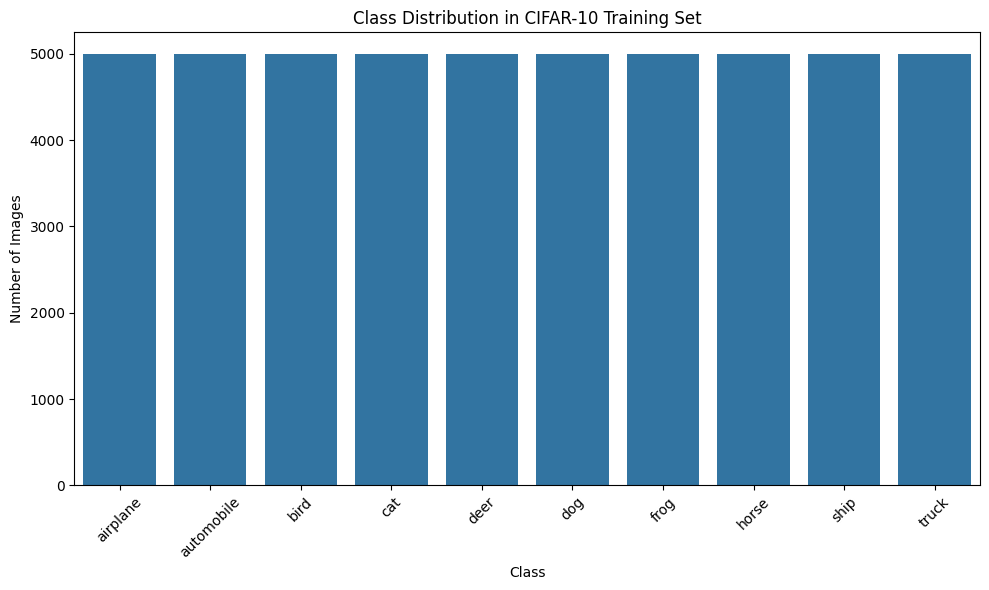

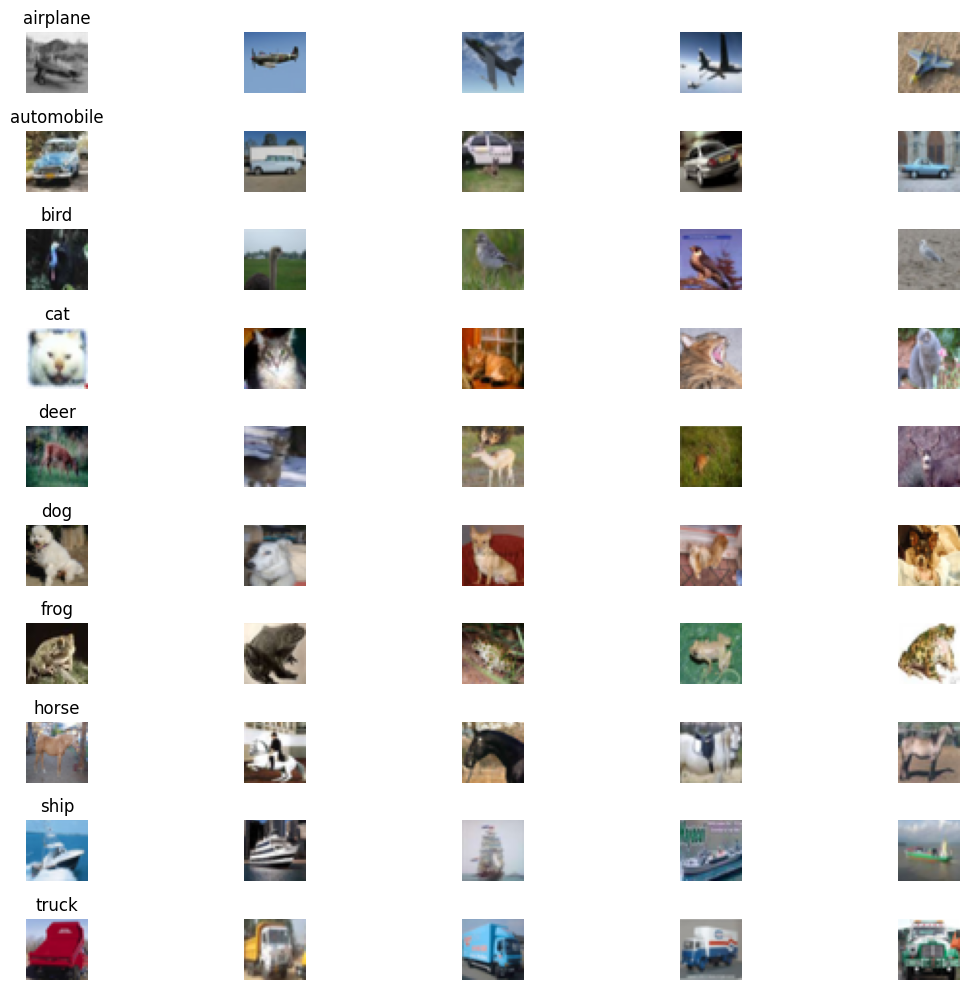


Checking for missing values:
Missing values in training data: 0
Missing values in training labels: 0
Missing values in test data: 0
Missing values in test labels: 0


In [3]:
# 2. Data Preprocessing and Exploration

# Define class names for CIFAR-10
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']

# EDA Visualization 1: Class Distribution
plt.figure(figsize=(10, 6))
class_counts = np.bincount(y_train.flatten())
sns.barplot(x=class_names, y=class_counts)
plt.title('Class Distribution in CIFAR-10 Training Set')
plt.xlabel('Class')
plt.ylabel('Number of Images')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('cifar10_class_distribution.png')
plt.show()

# EDA Visualization 2: Sample Images from Each Class
plt.figure(figsize=(12, 10))
for i in range(len(class_names)):
    # Get indices for each class
    indices = np.where(y_train == i)[0]

    # Randomly select 5 images from each class
    selected_indices = np.random.choice(indices, 5, replace=False)

    for j, idx in enumerate(selected_indices):
        plt.subplot(10, 5, i*5+j+1)
        plt.imshow(x_train[idx])
        plt.axis('off')
        if j == 0:
            plt.title(class_names[i])

plt.tight_layout()
plt.savefig('cifar10_sample_images.png')
plt.show()


# Check for missing values and data quality issues
print("\nChecking for missing values:")
print("Missing values in training data:", np.isnan(x_train).sum())
print("Missing values in training labels:", np.isnan(y_train).sum())
print("Missing values in test data:", np.isnan(x_test).sum())
print("Missing values in test labels:", np.isnan(y_test).sum())



170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 4s 0us/step


/usr/local/lib/python3.11/dist-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 30, 30, 32)          │             896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 15, 15, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 13, 13, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 6, 6, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 4, 4, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 2, 2, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │          65,664 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 160,202 (625.79 KB)

 Trainable params: 160,202 (625.79 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 75s 93ms/step - accuracy: 0.2805 - loss: 1.9067 - val_accuracy: 0.5093 - val_loss: 1.3417
Epoch 2/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 70s 89ms/step - accuracy: 0.4982 - loss: 1.3851 - val_accuracy: 0.5739 - val_loss: 1.1822
Epoch 3/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 83s 90ms/step - accuracy: 0.5671 - loss: 1.2253 - val_accuracy: 0.6142 - val_loss: 1.0751
Epoch 4/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 82s 90ms/step - accuracy: 0.6122 - loss: 1.1012 - val_accuracy: 0.6202 - val_loss: 1.0726
Epoch 5/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 82s 90ms/step - accuracy: 0.6439 - loss: 1.0163 - val_accuracy: 0.6730 - val_loss: 0.9342
Epoch 6/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 84s 92ms/step - accuracy: 0.6780 - loss: 0.9252 - val_accuracy: 0.6723 - val_loss: 0.9249
Epoch 7/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 81s 92ms/step - accuracy: 0.6938 - loss: 0.8766 - val_accuracy: 0.7026 - val_loss: 0.8552
Epoch 8/15
782/782 ━━━━━━━━━━━━━━━━━━━━ 82s 92ms/step - accuracy: 0.7112 - loss: 0.8293 - 

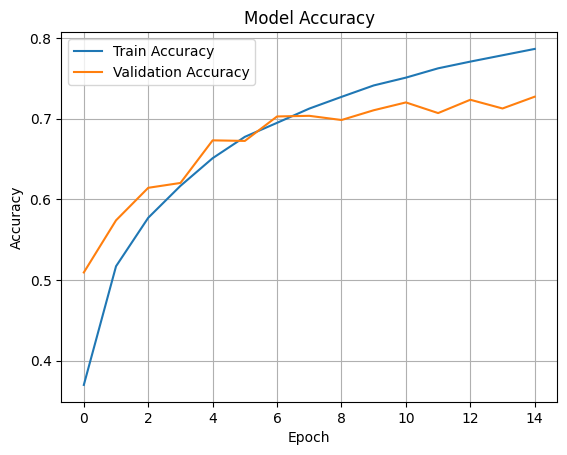

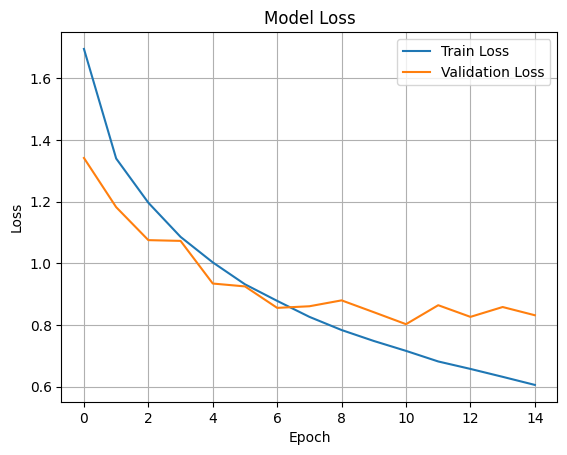

In [ ]:
#3. CNN Model Implementation (2*3 = 6 points)
# CIFAR-10 Image Classification using Keras

import tensorflow as tf
from tensorflow.keras.datasets import cifar10
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt

# 1. Load and preprocess CIFAR-10 data
(x_train, y_train), (x_test, y_test) = cifar10.load_data()

# Normalize pixel values
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# One-hot encode the labels
y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

# 2. Define the CNN model
model = Sequential([
    Conv2D(32, (3, 3), activation='relu', input_shape=(32, 32, 3)),
    MaxPooling2D((2, 2)),
    Conv2D(64, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Conv2D(128, (3, 3), activation='relu'),
    MaxPooling2D((2, 2)),
    Flatten(),
    Dense(128, activation='relu'),
    Dropout(0.5),
    Dense(10, activation='softmax')
])

model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

# 3. Train the model
history = model.fit(x_train, y_train,
                    epochs=15,
                    batch_size=64,
                    validation_data=(x_test, y_test))

# 4. Evaluate the model
loss, accuracy = model.evaluate(x_test, y_test)
print(f'\nTest Accuracy: {accuracy:.2%}')

# 5. Plot training & validation accuracy
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Model Accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend()
plt.grid()
plt.show()

# 6. Plot training & validation loss
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Model Loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend()
plt.grid()
plt.show()

x_train shape: (50000, 32, 32, 3) - y_train shape: (50000, 1)
x_test shape: (10000, 32, 32, 3) - y_test shape: (10000, 1)
Epoch 1/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 1380s 4s/step - accuracy: 0.2694 - loss: 1.9469 - val_accuracy: 0.4448 - val_loss: 1.4811
Epoch 2/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 1342s 4s/step - accuracy: 0.4456 - loss: 1.5092 - val_accuracy: 0.5142 - val_loss: 1.3196
Epoch 3/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 1350s 4s/step - accuracy: 0.5178 - loss: 1.3343 - val_accuracy: 0.5750 - val_loss: 1.1766
Epoch 4/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 1428s 4s/step - accuracy: 0.5523 - loss: 1.2456 - val_accuracy: 0.5938 - val_loss: 1.1144
Epoch 5/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 1408s 4s/step - accuracy: 0.5780 - loss: 1.1754 - val_accuracy: 0.6278 - val_loss: 1.0383
Epoch 6/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 1405s 4s/step - accuracy: 0.6010 - loss: 1.1203 - val_accuracy: 0.6276 - val_loss: 1.0441
Epoch 7/15
352/352 ━━━━━━━━━━━━━━━━━━━━ 1386s 4s/step - accuracy: 0.6159 - loss: 1.0709 - val_accu

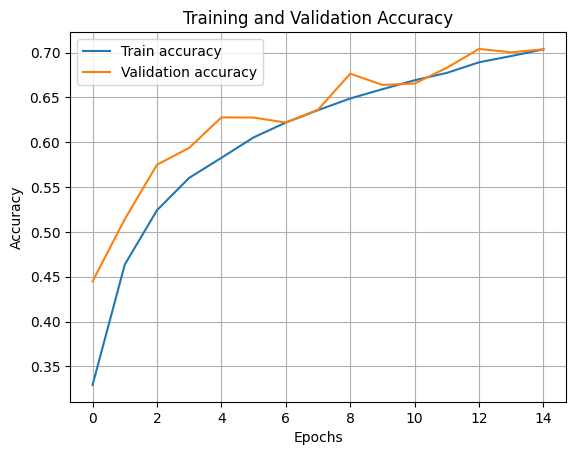

In [ ]:
#4. Transformer Model Implementation (2*3 = 6 points)
# -*- coding: utf-8 -*-
"""image_classification_with_vision_transformer_cifar10

This example implements the Vision Transformer (ViT) model by Alexey Dosovitskiy et al.
for image classification, demonstrating it on the CIFAR-10 dataset.

## Setup
"""

import keras
from keras import layers
from keras import ops

import numpy as np
import matplotlib.pyplot as plt

"""## Prepare the data"""

num_classes = 10
input_shape = (32, 32, 3)

(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()

print(f"x_train shape: {x_train.shape} - y_train shape: {y_train.shape}")
print(f"x_test shape: {x_test.shape} - y_test shape: {y_test.shape}")

"""## Configure the hyperparameters"""

learning_rate = 0.001
weight_decay = 0.0001
batch_size = 128
num_epochs = 15
image_size = 72
patch_size = 6
num_patches = (image_size // patch_size) ** 2
projection_dim = 64
num_heads = 4
transformer_units = [projection_dim * 2, projection_dim]
transformer_layers = 4
mlp_head_units = [512, 256]

"""## Data augmentation"""

data_augmentation = keras.Sequential([
    layers.Normalization(),
    layers.Resizing(image_size, image_size),
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.02),
    layers.RandomZoom(0.1, 0.1)
], name="data_augmentation")
data_augmentation.layers[0].adapt(x_train)

"""## Define MLP"""

def mlp(x, hidden_units, dropout_rate):
    for units in hidden_units:
        x = layers.Dense(units, activation=keras.activations.gelu)(x)
        x = layers.Dropout(dropout_rate)(x)
    return x

"""## Define Patches layer"""

class Patches(layers.Layer):
    def __init__(self, patch_size):
        super().__init__()
        self.patch_size = patch_size

    def call(self, images):
        patches = ops.image.extract_patches(images, size=self.patch_size)
        batch_size = ops.shape(images)[0]
        patches = ops.reshape(patches, [batch_size, -1, patches.shape[-1]])
        return patches

"""## Define Patch Encoder"""

class PatchEncoder(layers.Layer):
    def __init__(self, num_patches, projection_dim):
        super().__init__()
        self.projection = layers.Dense(projection_dim)
        self.position_embedding = layers.Embedding(num_patches, projection_dim)

    def call(self, patches):
        positions = ops.arange(start=0, stop=num_patches, step=1)
        projected_patches = self.projection(patches)
        return projected_patches + self.position_embedding(positions)

"""## Build ViT model"""

def create_vit_classifier():
    inputs = keras.Input(shape=input_shape)
    augmented = data_augmentation(inputs)
    patches = Patches(patch_size)(augmented)
    encoded_patches = PatchEncoder(num_patches, projection_dim)(patches)

    for _ in range(transformer_layers):
        x1 = layers.LayerNormalization()(encoded_patches)
        attention_output = layers.MultiHeadAttention(num_heads=num_heads, key_dim=projection_dim)(x1, x1)
        x2 = layers.Add()([attention_output, encoded_patches])
        x3 = layers.LayerNormalization()(x2)
        x3 = mlp(x3, transformer_units, dropout_rate=0.1)
        encoded_patches = layers.Add()([x3, x2])

    representation = layers.LayerNormalization()(encoded_patches)
    representation = layers.GlobalAveragePooling1D()(representation)
    features = mlp(representation, mlp_head_units, dropout_rate=0.5)
    logits = layers.Dense(num_classes)(features)

    model = keras.Model(inputs=inputs, outputs=logits)
    return model

"""## Compile, train, and evaluate the model"""

def run_experiment(model):
    optimizer = keras.optimizers.AdamW(learning_rate=learning_rate, weight_decay=weight_decay)

    model.compile(
        optimizer=optimizer,
        loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True),
        metrics=["accuracy"]
    )

    history = model.fit(
        x=x_train, y=y_train,
        batch_size=batch_size,
        epochs=num_epochs,
        validation_split=0.1
    )

    _, accuracy = model.evaluate(x_test, y_test)
    print(f"Test accuracy: {accuracy:.2%}")

    return history

vit_classifier = create_vit_classifier()
history = run_experiment(vit_classifier)

"""## Plot results"""

plt.plot(history.history["accuracy"], label="Train accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Training and Validation Accuracy")
plt.legend()
plt.grid()
plt.show()
